# Primer Parcial
**Nombre:** Jhon Carlos Condori Cuevas.  **Carrera:** Ing. de Sistemas<br>
Dataset: **ESC-50 (Environmental Sound Classification)**
(https://www.kaggle.com/datasets/mmoreaux/environmental-sound-classification-50)<br>
**Repositorio:** https://github.com/jccondoric/machine_learning/blob/master/Parciales/Primer_Parcial.ipynb

ESC-50 es un dataset de clasificación de sonidos ambientales con 2,000 audios WAV de 5 segundos a 16 kHz, distribuidos en 50 clases balanceadas (40 audios por clase). Incluye un archivo esc50.csv con metadata y un fold oficial (1-5) para hacer una división train/test reproducible (folds 1-4 train, fold 5 test). Se usa como benchmark para evaluar modelos de clasificación de audio multiclase

## 1. Conectar Google Drive

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
import os

BASE_DIR = "/content/drive/MyDrive/IA/Parciales/Primer_Parcial"
AUDIO_DIR = os.path.join(BASE_DIR, "audio", "16000")
CSV_PATH = os.path.join(BASE_DIR, "esc50.csv")

print("¿Existe la carpeta de audio?", os.path.isdir(AUDIO_DIR))
print("¿Existe esc50.csv?", os.path.isfile(CSV_PATH))
print("N° de archivos .wav encontrados:", len([f for f in os.listdir(AUDIO_DIR) if f.endswith('.wav')]))

¿Existe la carpeta de audio? True
¿Existe esc50.csv? True
N° de archivos .wav encontrados: 2000


## 2. Metadata del dataset

`esc50.csv` contiene, para cada archivo de audio, la siguiente información:

- **`filename`**: nombre del archivo `.wav` dentro de la carpeta de audio.
- **`category`**: nombre legible de la clase (por ejemplo, `dog`, `rain`, `siren`).
- **`target`**: número de clase entre 0 y 49 (lo que usaremos como etiqueta `y`).
- **`fold`**: partición oficial (1 a 5) a la que pertenece el audio.

In [3]:
import pandas as pd

meta = pd.read_csv(CSV_PATH)
meta.head()

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


In [4]:
print("Número de audios en el csv:", len(meta))
print("Número de clases:", meta['target'].nunique())
meta['category'].value_counts().head(10)

Número de audios en el csv: 2000
Número de clases: 50


,count
category,
dog,40
chirping_birds,40
vacuum_cleaner,40
thunderstorm,40
door_wood_knock,40
can_opening,40
crow,40
clapping,40
fireworks,40


### 2.1 Balance de clases

El dataset si está balanceado (40 ejemplos por clase).

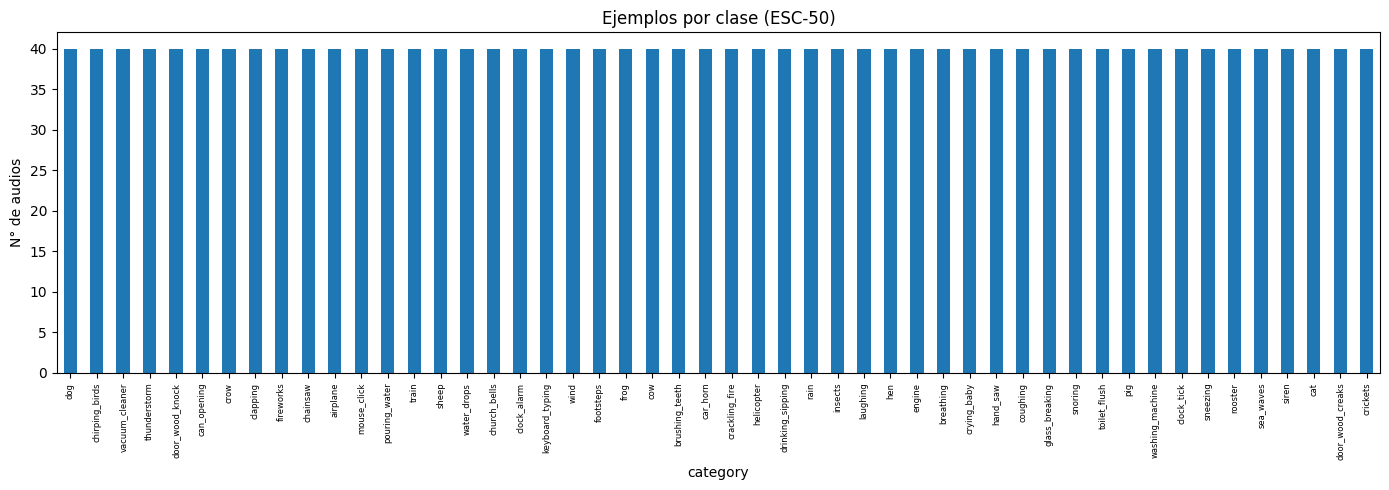

Mínimo de ejemplos por clase: 40
Máximo de ejemplos por clase: 40


In [5]:
import matplotlib.pyplot as plt

conteo = meta['category'].value_counts()
plt.figure(figsize=(14, 5))
conteo.plot(kind='bar')
plt.title("Ejemplos por clase (ESC-50)")
plt.ylabel("N° de audios")
plt.xticks(fontsize=6)
plt.tight_layout()
plt.show()

print("Mínimo de ejemplos por clase:", conteo.min())
print("Máximo de ejemplos por clase:", conteo.max())

## 3. Extracción de características (MFCC: media + desviación estándar)

Cada audio se convierte primero en una matriz de coeficientes MFCC (40 coeficientes × N ventanas de tiempo).
En vez de aplanar toda la matriz, resumimos cada coeficiente con su **media** y **desviación estándar** a lo
largo del tiempo (con `numpy`), obteniendo un vector fijo de 80 valores por audio.

In [7]:
!pip install librosa -q

In [8]:
import librosa
import numpy as np

SR = 16000
DURATION = 5
N_MFCC = 40
SAMPLES = SR * DURATION

def extract_mfcc_stats(filepath):
    y, sr = librosa.load(filepath, sr=SR)
    if len(y) < SAMPLES:
        y = np.pad(y, (0, SAMPLES - len(y)))
    else:
        y = y[:SAMPLES]
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
    return np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)])

### 3.1 Extraer características de todos los audios (con caché)


In [9]:
import torch

FEATURES_PATH = os.path.join(BASE_DIR, "esc50_mfcc_stats.pt")

if os.path.isfile(FEATURES_PATH):
    print("Cargando")
    data = torch.load(FEATURES_PATH)
    X = data['X']
    y = data['y']
else:
    print("Extrayendo")
    X_list, y_list = [], []
    for idx, row in meta.iterrows():
        filepath = os.path.join(AUDIO_DIR, row['filename'])
        features = extract_mfcc_stats(filepath)
        X_list.append(features)
        y_list.append(row['target'])
        if (idx + 1) % 200 == 0:
            print(f"  Procesados {idx + 1}/{len(meta)}")

    X = torch.tensor(np.array(X_list), dtype=torch.float32)
    y = torch.tensor(np.array(y_list), dtype=torch.long)

    torch.save({'X': X, 'y': y}, FEATURES_PATH)
    print("Características guardadas en:", FEATURES_PATH)

X.shape, y.shape

Extrayendo
  Procesados 200/2000
  Procesados 400/2000
  Procesados 600/2000
  Procesados 800/2000
  Procesados 1000/2000
  Procesados 1200/2000
  Procesados 1400/2000
  Procesados 1600/2000
  Procesados 1800/2000
  Procesados 2000/2000
Características guardadas en: /content/drive/MyDrive/IA/Parciales/Primer_Parcial/esc50_mfcc_stats.pt


(torch.Size([2000, 80]), torch.Size([2000]))

## 4. División train / validación / test

Usando la columna `fold` del csv: folds 1-4 para entrenamiento, fold 5 para prueba. Del conjunto de
entrenamiento se separa un 10% como validación, para ver si el modelo empieza a sobreajustar. La separación
se hace con `np.random.permutation`

In [12]:
fold = meta['fold'].values

train_idx = fold != 5
test_idx = fold == 5

X_train_full, y_train_full = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

np.random.seed(42)
n_train_full = len(X_train_full)
perm = np.random.permutation(n_train_full)
n_val = int(0.1 * n_train_full)

val_idx = perm[:n_val]
tr_idx = perm[n_val:]

X_tr, y_tr = X_train_full[tr_idx], y_train_full[tr_idx]
X_val, y_val = X_train_full[val_idx], y_train_full[val_idx]

X_tr.shape, X_val.shape, X_test.shape

(torch.Size([1440, 80]), torch.Size([160, 80]), torch.Size([400, 80]))

### 4.1 Normalización

Cada una de las 80 características se normaliza restando su media y dividiendo entre su desviación estándar,
calculadas solo con `X_tr` y aplicadas igual a validación y test.

In [13]:
X_tr_np = X_tr.numpy()

feature_mean = X_tr_np.mean(axis=0)
feature_std = X_tr_np.std(axis=0) + 1e-8

X_tr = torch.tensor((X_tr.numpy() - feature_mean) / feature_std, dtype=torch.float32)
X_val = torch.tensor((X_val.numpy() - feature_mean) / feature_std, dtype=torch.float32)
X_test = torch.tensor((X_test.numpy() - feature_mean) / feature_std, dtype=torch.float32)

X_tr.mean(), X_tr.std()

(tensor(1.2665e-07), tensor(1.0000))

## 5. Dataset y DataLoader

`Dataset` personalizado y `DataLoader` para entrenar por batches.

In [14]:
from torch.utils.data import Dataset, DataLoader

class ESC50Dataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_dataset = ESC50Dataset(X_tr, y_tr)
val_dataset = ESC50Dataset(X_val, y_val)
test_dataset = ESC50Dataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

len(train_dataset), len(val_dataset), len(test_dataset)

(1440, 160, 400)

## 6. Modelo (Red Neuronal en PyTorch)

`nn.Sequential` con una capa oculta `ReLU`. Entrada: 80 neuronas (media + std de MFCC). Salida: 50 neuronas
(una por clase).

In [17]:
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

input_size = X_tr.shape[1]
hidden_size = 64
num_classes = 50

model = nn.Sequential(
    nn.Linear(input_size, hidden_size),
    nn.ReLU(),
    nn.Linear(hidden_size, num_classes)
).to(device)

model

Usando dispositivo: cpu


Sequential(
  (0): Linear(in_features=80, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=50, bias=True)
)

### 6.1 Función de pérdida y optimizador

In [18]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

### 6.2 Entrenamiento (con validación por época)

Se mide loss y accuracy en train y validación en cada época, para ver si el modelo empieza a sobreajustar.

In [19]:
def evaluate_loader(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            total_loss += loss.item() * len(y_batch)
            correct += (outputs.argmax(dim=1) == y_batch).sum().item()
            total += len(y_batch)
    return total_loss / total, correct / total


EPOCHS = 100
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(EPOCHS):
    model.train()
    epoch_loss, correct, total = 0.0, 0, 0

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(y_batch)
        correct += (outputs.argmax(dim=1) == y_batch).sum().item()
        total += len(y_batch)

    train_loss = epoch_loss / total
    train_acc = correct / total
    val_loss, val_acc = evaluate_loader(model, val_loader, criterion, device)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS} - train_loss: {train_loss:.4f} - val_loss: {val_loss:.4f} "
              f"- train_acc: {train_acc:.4f} - val_acc: {val_acc:.4f}")

Epoch 10/100 - train_loss: 2.3601 - val_loss: 2.4331 - train_acc: 0.4014 - val_acc: 0.3563
Epoch 20/100 - train_loss: 1.5474 - val_loss: 1.8776 - train_acc: 0.6042 - val_acc: 0.4437
Epoch 30/100 - train_loss: 1.1241 - val_loss: 1.7305 - train_acc: 0.7347 - val_acc: 0.4938
Epoch 40/100 - train_loss: 0.8745 - val_loss: 1.6470 - train_acc: 0.7951 - val_acc: 0.5250
Epoch 50/100 - train_loss: 0.7048 - val_loss: 1.6092 - train_acc: 0.8472 - val_acc: 0.5375
Epoch 60/100 - train_loss: 0.5783 - val_loss: 1.6071 - train_acc: 0.8792 - val_acc: 0.5375
Epoch 70/100 - train_loss: 0.4801 - val_loss: 1.6541 - train_acc: 0.8972 - val_acc: 0.5375
Epoch 80/100 - train_loss: 0.4009 - val_loss: 1.7049 - train_acc: 0.9278 - val_acc: 0.5500
Epoch 90/100 - train_loss: 0.3395 - val_loss: 1.7324 - train_acc: 0.9403 - val_acc: 0.5437
Epoch 100/100 - train_loss: 0.2894 - val_loss: 1.7355 - train_acc: 0.9521 - val_acc: 0.5813


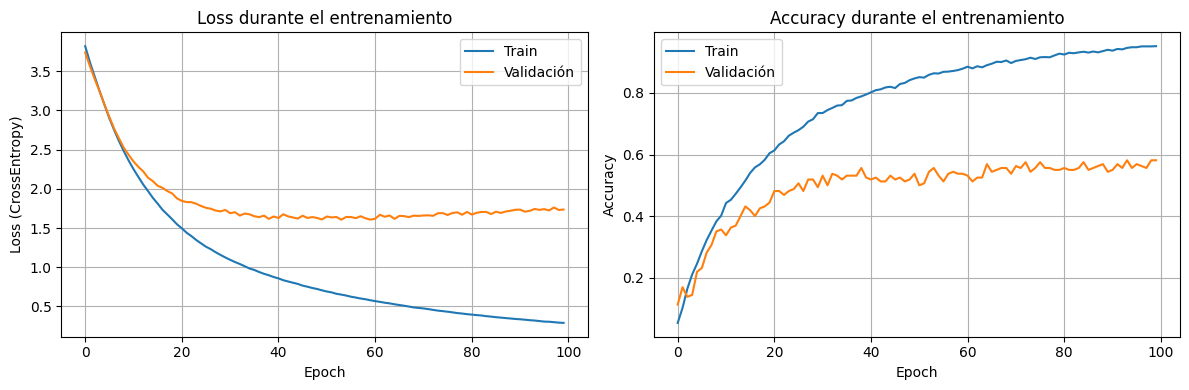

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['val_loss'], label='Validación')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss (CrossEntropy)")
axes[0].set_title("Loss durante el entrenamiento")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history['train_acc'], label='Train')
axes[1].plot(history['val_acc'], label='Validación')
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy durante el entrenamiento")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### 6.3 Guardar el modelo entrenado

Además de los pesos, se guardan `feature_mean` y `feature_std`, los valores usados para normalizar.

In [21]:
MODEL_PATH = os.path.join(BASE_DIR, "esc50_model.pt")

torch.save({
    'model_state': model.state_dict(),
    'input_size': input_size,
    'hidden_size': hidden_size,
    'num_classes': num_classes,
    'feature_mean': feature_mean,
    'feature_std': feature_std,
}, MODEL_PATH)

print("Modelo guardado en:", MODEL_PATH)

Modelo guardado en: /content/drive/MyDrive/IA/Parciales/Primer_Parcial/esc50_model.pt


## 7. Predicción

In [22]:
def predict(model, X, device):
    model.eval()
    with torch.no_grad():
        X = X.to(device)
        logits = model(X)
        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)
    return preds.cpu().numpy(), probs.cpu().numpy()


pred_train, proba_train = predict(model, X_tr, device)
pred_test, proba_test = predict(model, X_test, device)

y_tr_np = y_tr.numpy()
y_test_np = y_test.numpy()

print('Training Set Accuracy: %f' % (np.mean(pred_train == y_tr_np) * 100))
print('Test Set Accuracy: %f' % (np.mean(pred_test == y_test_np) * 100))

Training Set Accuracy: 95.555556
Test Set Accuracy: 41.500000


## 8. Métricas de clasificación (multiclase)

Para 50 clases se usa `average='macro'` (promedia el valor de cada clase por igual) y ROC/AUC con enfoque
"uno contra el resto" (`multi_class='ovr'`).

### 8.1 Accuracy

In [23]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test_np, pred_test)

0.415

In [24]:
1 / num_classes

0.02

### 8.2 Matriz de confusión

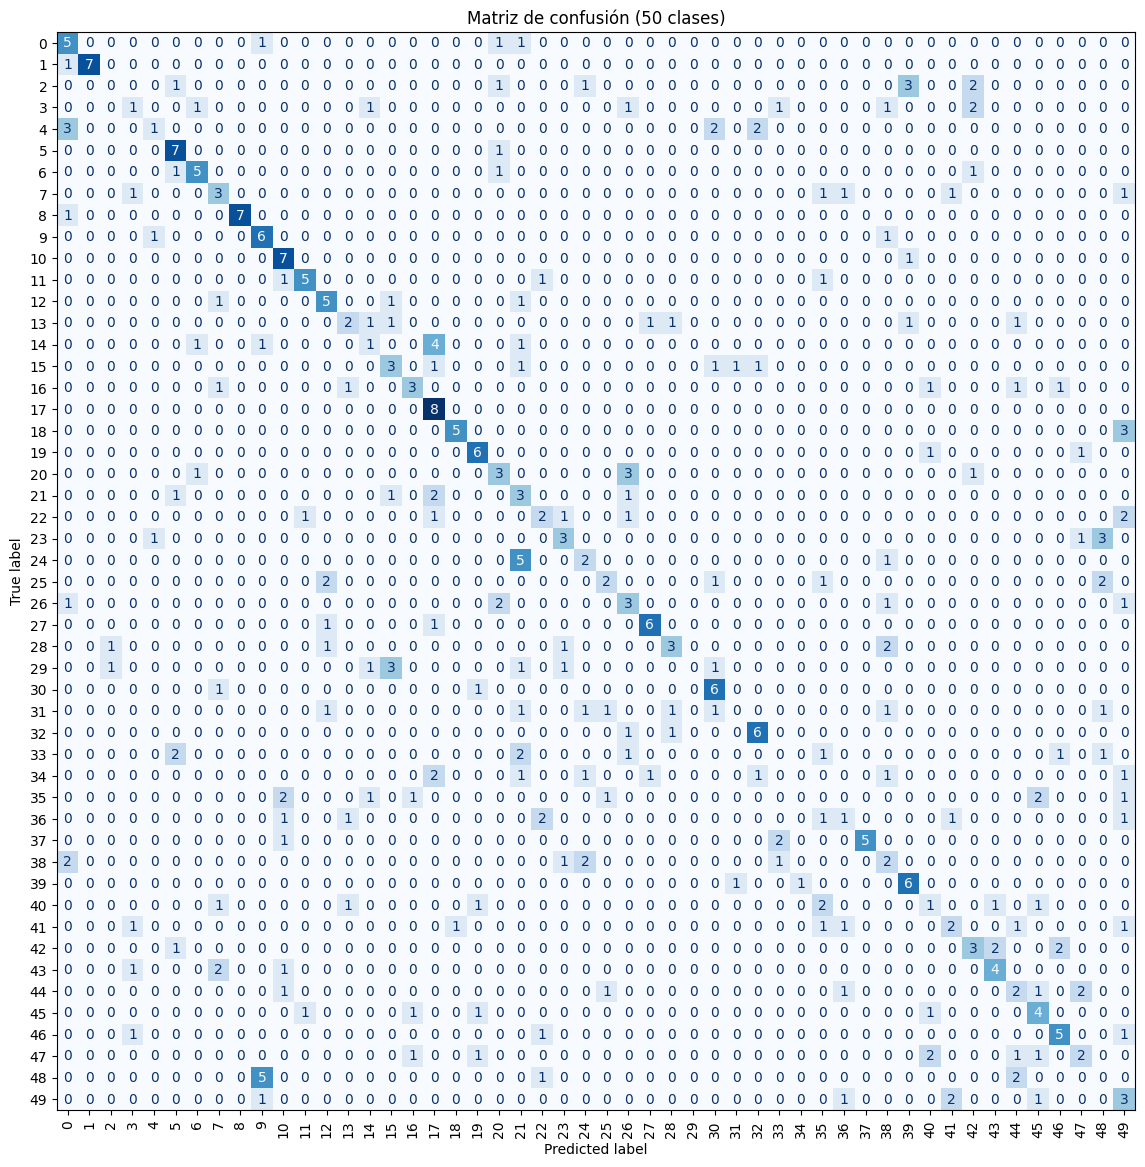

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_np, pred_test)

plt.figure(figsize=(16, 14))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(ax=plt.gca(), cmap="Blues", colorbar=False, xticks_rotation=90)
plt.title("Matriz de confusión (50 clases)")
plt.show()

### 8.3 Precision, Recall y F1 (macro)

In [26]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision_macro = precision_score(y_test_np, pred_test, average='macro', zero_division=0)
recall_macro = recall_score(y_test_np, pred_test, average='macro', zero_division=0)
f1_macro = f1_score(y_test_np, pred_test, average='macro', zero_division=0)

print("Precision (macro):", precision_macro)
print("Recall (macro):", recall_macro)
print("F1-score (macro):", f1_macro)

Precision (macro): 0.3893391312849517
Recall (macro): 0.415
F1-score (macro): 0.3891949554555961


In [27]:
from sklearn.metrics import classification_report

categorias = meta.sort_values('target').drop_duplicates('target')['category'].values

print(classification_report(y_test_np, pred_test, target_names=categorias, zero_division=0))

                  precision    recall  f1-score   support

             dog       0.38      0.62      0.48         8
         rooster       1.00      0.88      0.93         8
             pig       0.00      0.00      0.00         8
             cow       0.20      0.12      0.15         8
            frog       0.33      0.12      0.18         8
             cat       0.54      0.88      0.67         8
             hen       0.62      0.62      0.62         8
         insects       0.33      0.38      0.35         8
           sheep       1.00      0.88      0.93         8
            crow       0.43      0.75      0.55         8
            rain       0.50      0.88      0.64         8
       sea_waves       0.71      0.62      0.67         8
  crackling_fire       0.50      0.62      0.56         8
        crickets       0.40      0.25      0.31         8
  chirping_birds       0.20      0.12      0.15         8
     water_drops       0.33      0.38      0.35         8
            w

### 8.4 ¿Qué clases se confunden más?

Se listan los pares de clases con más errores entre sí.

In [28]:
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)

n_top = 10
flat_idx = np.argsort(cm_no_diag, axis=None)[::-1][:n_top]
rows, cols = np.unravel_index(flat_idx, cm_no_diag.shape)

print("Pares de clases más confundidos (real -> predicho : cantidad de errores)")
for r, c in zip(rows, cols):
    if cm_no_diag[r, c] > 0:
        print(f"  {categorias[r]} -> {categorias[c]} : {cm_no_diag[r, c]}")

Pares de clases más confundidos (real -> predicho : cantidad de errores)
  coughing -> sneezing : 5
  fireworks -> crow : 5
  chirping_birds -> pouring_water : 4
  frog -> dog : 3
  crying_baby -> laughing : 3
  pig -> glass_breaking : 3
  breathing -> fireworks : 3
  toilet_flush -> hand_saw : 3
  drinking_sipping -> water_drops : 3
  vacuum_cleaner -> clapping : 2


### 8.5 Curva ROC y AUC (uno contra el resto)

In [29]:
from sklearn.metrics import roc_auc_score

auc_macro = roc_auc_score(y_test_np, proba_test, multi_class='ovr', average='macro')
print("AUC (macro, one-vs-rest):", auc_macro)

AUC (macro, one-vs-rest): 0.9211670918367346


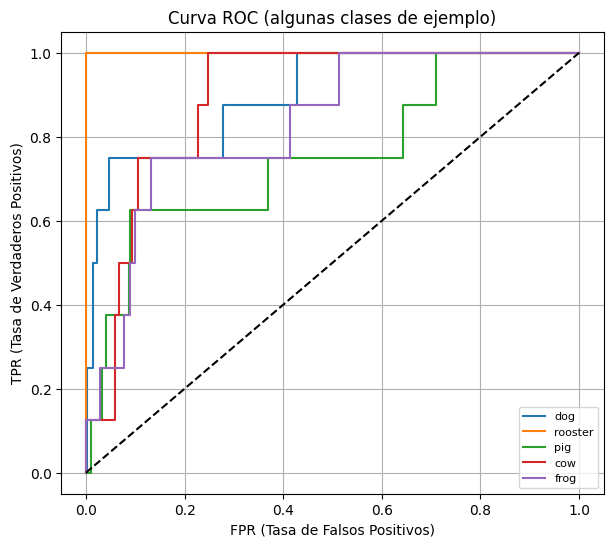

In [30]:
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize

y_test_bin = label_binarize(y_test_np, classes=list(range(num_classes)))

clases_ejemplo = [0, 1, 2, 3, 4]  # cambia estos índices si quieres ver otras clases

plt.figure(figsize=(7, 6))
for c in clases_ejemplo:
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], proba_test[:, c])
    plt.plot(fpr, tpr, label=f"{categorias[c]}")

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('FPR (Tasa de Falsos Positivos)')
plt.ylabel('TPR (Tasa de Verdaderos Positivos)')
plt.title("Curva ROC (algunas clases de ejemplo)")
plt.legend(fontsize=8)
plt.grid(True)
plt.show()

## 9. Resumen

Entrenamos una red neuronal (`nn.Sequential`: Linear → ReLU → Linear) en PyTorch, usando exactamente las
herramientas de `01_pytorch_intro`, `02_pytorch_nn`, `03_pytorch_datasets` y `04_pytorch_save` (sin agregar
`Adam`, `Dropout`, `BatchNorm` ni otras clases no vistas en clase), sobre el dataset **ESC-50** (clasificación
de sonidos ambientales, 50 clases balanceadas, versión original por clip de 5 segundos).

- Cada audio se resumió en un vector de 80 características (media + desviación estándar de sus MFCC, calculadas
  con `numpy`), en vez de aplanar toda la matriz, para evitar una entrada demasiado grande frente a la cantidad
  de datos disponibles.
- La normalización de características se hizo manualmente con `numpy` (resta de media, división por desviación
  estándar calculadas solo en train), igual que ya se normalizaban los píxeles en MNIST.
- Se separó un conjunto de validación (barajando índices con `np.random.permutation`) para monitorear
  overfitting durante el entrenamiento, además del test (fold 5 oficial de ESC-50).
- Se entrenó con `CrossEntropyLoss` + `SGD`, igual que en `02_pytorch_nn`.
- Se evaluó con las métricas del notebook `08_metricas_clasificacion` adaptadas a multiclase: accuracy, matriz
  de confusión (50×50), precision/recall/F1 (`average='macro'`), curva ROC/AUC "uno contra el resto", y un
  análisis de las clases más confundidas entre sí.